In [6]:
import numpy as np
import rebound
from scipy.optimize import fsolve
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.animation import PillowWriter

In [7]:
# Define Constants
G = 1 # Gravitational constant in arbitrary units
m1 = 10 # Mass of the first body
m2 = 1 # Mass of the second body

R = 10 # Distance between the two bodies in the original frame
_r1 = np.array([-R/2, 0]) # Position of the first body in the original frame
_r2 = np.array([R/2, 0]) # Position of the second body in the original frame
r_com = (m1*_r1 + m2*_r2) / (m1 + m2)
r1 = _r1 - r_com # Position of the first body relative to the center of mass
r2 = _r2 - r_com # Position of the second body relative to the center of mass

Ω = np.sqrt(G * (m1 + m2) / R**3) # Angular velocity of the rotating frame

In [8]:
# Numeric calculation of the Lagrange points

# Define α and β parameters
α = m2 / (m1 + m2)
β = m1 / (m1 + m2)

# Define force function
def force(coord: tuple, mass_ratios = (α, β)) -> tuple:
    """Gives the force of the force at a point (x, y)

    Args:
        x float: x-coordinate of the point
        y float: y-coordinate of the point
    Returns:
        tuple: Force components (fx, fy) at the point (x, y)
    """
    x, y = coord
    α, β = mass_ratios
    Ω2 = np.dot(Ω, Ω)
    # Define the force components
    fx = Ω2 * (x - (β*(x + α*R)*R**3)/((x + α*R)**2 + y**2)**(3/2) - (α*(x - β*R)*R**3)/((x - β*R)**2 + y**2)**(3/2))
    fy = Ω2 * (y - (β*y*R**3)/((x + α*R)**2 + y**2)**(3/2) - (α*y*R**3)/((x - β*R)**2 + y**2)**(3/2))
    return fx, fy

# Define function to find Lagrange points
def find_lagrange_point(guess: tuple, mass_ratios = (α, β)) -> tuple:
    """Finds the Lagrange point given an initial guess

    Args:
        guess (tuple): Initial guess for the Lagrange point (x, y)
    Returns:
        tuple: Coordinates of the Lagrange point (x, y)
    """
    def f(coord, mass_ratios = (α, β)):
        return force(coord, mass_ratios)
    gx = guess[0]
    gy = guess[1]
    lx = fsolve(f, (gx, gy))[0]
    ly = fsolve(f, (gx, gy))[1]
    return (lx, ly)

# Find Lagrange points numerically
lp = [
    find_lagrange_point((R/2, 0)),  # L1
    find_lagrange_point((3*R/2, 0)),  # L2
    find_lagrange_point((-R, 0)), # L3
    find_lagrange_point((R/2, np.sqrt(3)*R/2)),  # L4
    find_lagrange_point((R/2, -np.sqrt(3)*R/2))  # L5
]

In [ ]:
try:
    # Attempt to load saved simulation state
    sim = rebound.Simulation("data/initial_state.bin")
except:
    # Create a new simulation if the saved state does not exist
    sim = rebound.Simulation()

    # Define two massive bodies
    p1 = rebound.Particle(m=m1, x=r1[0], y=r1[1], z=0, vx=0, vy=Ω*r1[0], vz=0)
    p2 = rebound.Particle(m=m2, x=r2[0], y=r2[1], z=0, vx=0, vy=Ω*r2[0], vz=0)

    sim.add(p1)
    sim.add(p2)

    # Define a test particles at the Lagrange points
    l1 = rebound.Particle(m=0, x=lp[0][0], y=lp[0][1], z=0, vx=0, vy=lp[0][0]*Ω, vz=0)
    l2 = rebound.Particle(m=0, x=lp[1][0], y=lp[1][1], z=0, vx=0, vy=lp[1][0]*Ω, vz=0)
    l3 = rebound.Particle(m=0, x=lp[2][0], y=lp[2][1], z=0, vx=0, vy=lp[2][0]*Ω, vz=0)
    l4 = rebound.Particle(m=0, x=lp[3][0], y=lp[3][1], z=0, vx=-lp[3][1]*Ω, vy=lp[3][0]*Ω, vz=0)
    l5 = rebound.Particle(m=0, x=lp[4][0], y=lp[4][1], z=0, vx=-lp[4][1]*Ω, vy=lp[4][0]*Ω, vz=0)

    sim.add(l1)
    sim.add(l2)
    sim.add(l3)
    sim.add(l4)
    sim.add(l5)

    # Move the simulation to the center of mass frame
    sim.move_to_com()
    
    # Save the initial state of the simulation to a file for future use
    sim.save_to_file("data/initial_state.bin")

Position Perturbation: Δx=-0.056, Δy=0.034
Perturbed L1: x=6.210, y=0.034, vx=0.000, vy=0.657
Position Perturbation: Δx=-0.197, Δy=-0.003
Perturbed L2: x=12.364, y=-0.003, vx=0.000, vy=1.317
Position Perturbation: Δx=0.035, Δy=-0.068
Perturbed L3: x=-10.344, y=-0.068, vx=0.000, vy=-1.088
Position Perturbation: Δx=-0.073, Δy=-0.034
Perturbed L4: x=4.018, y=8.627, vx=-0.908, vy=0.429
Position Perturbation: Δx=-0.206, Δy=-0.002
Perturbed L5: x=3.885, y=-8.662, vx=0.908, vy=0.429


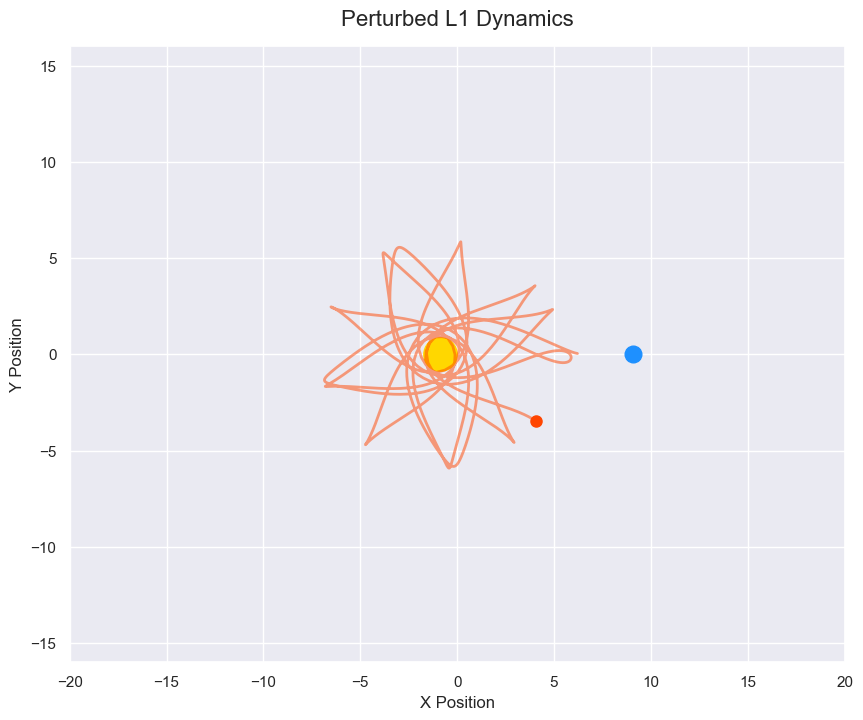

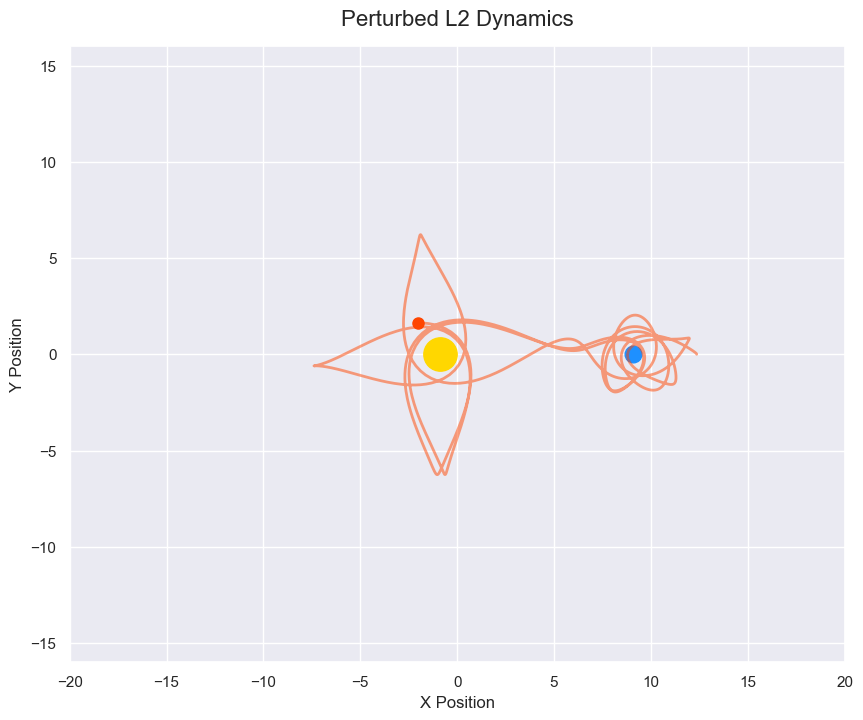

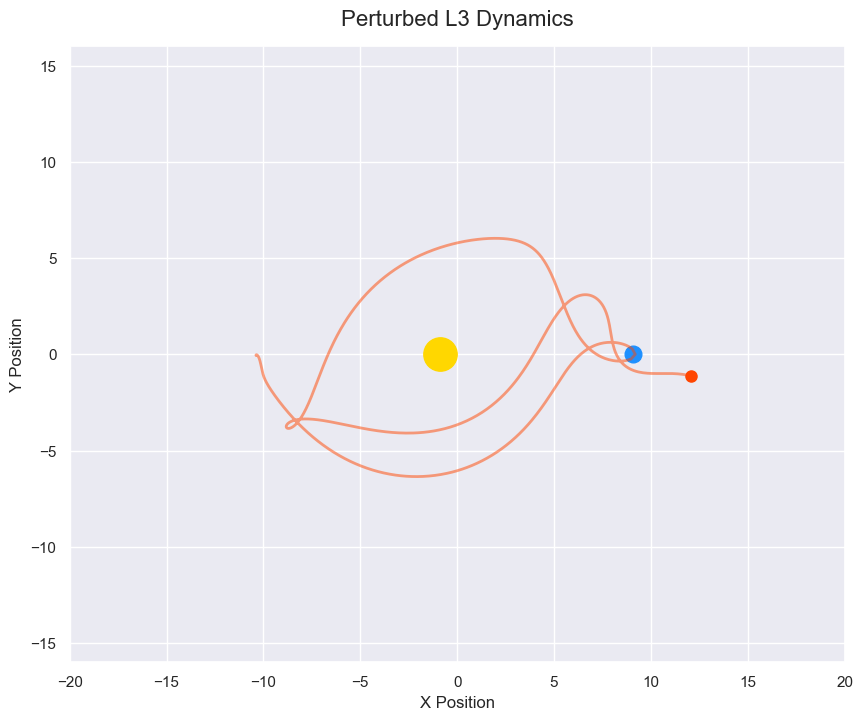

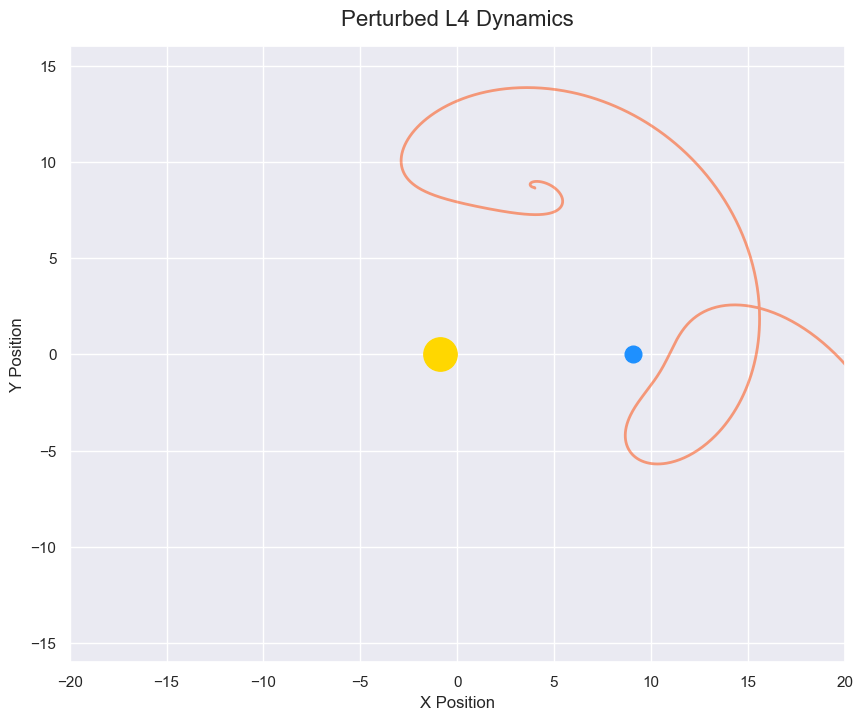

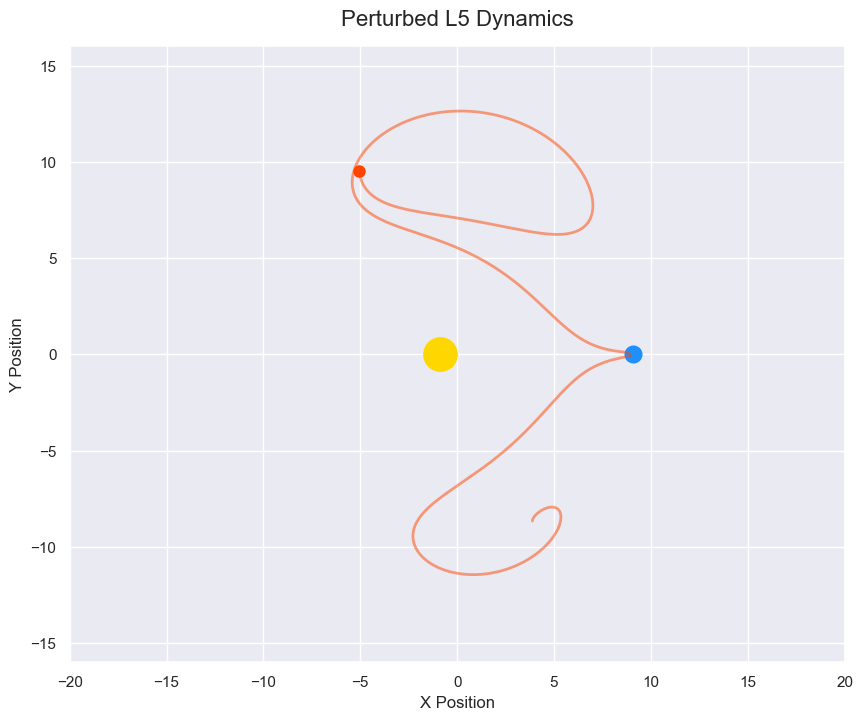

In [ ]:
sns.set_theme(style="darkgrid")

for i in range(5):
    # Reload simulation to reset the positions of the test particles
    sim = rebound.Simulation("data/initial_state.bin")
    
    # Add a small perturbation to the test particle's position
    perturbation = np.random.normal(0, 0.1, size=2)  # Small random perturbation
    sim.particles[2 + i].x += perturbation[0]
    sim.particles[2 + i].y += perturbation[1]
    
    print(f"Position Perturbation: Δx={perturbation[0]:.3f}, Δy={perturbation[1]:.3f}")
    print(f"Perturbed L{1+i}: x={sim.particles[2+i].x:.3f}, y={sim.particles[2+i].y:.3f}, vx={sim.particles[2+i].vx:.3f}, vy={sim.particles[2+i].vy:.3f}")
    
    # Initialize the plot
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.set_title(f"Perturbed L{i+1} Dynamics", fontsize=16, pad=15)
    
    ax.set_xlabel("X Position")
    ax.set_ylabel("Y Position")

    ax.set_xlim(-20, 20)
    ax.set_ylim(-16, 16)

    # Initialize plot elements for current positions
    p1_point, = ax.plot([], [], color='gold', marker='o', markersize=24)
    p2_point, = ax.plot([], [], color='dodgerblue', marker='o', markersize=12)  
    p3_point, = ax.plot([], [], color='orangered', marker='o', markersize=8)  

    # Initialize plot element for the test particle's trail
    trail_x, trail_y = [], []
    trail_line, = ax.plot([], [], color='orangered', alpha=0.5, lw=2)

    # Set up the animation writer
    writer = PillowWriter(fps=30)
    interval = 0.1

    with writer.saving(fig, f"plots/l{i+1}.gif", dpi=100):
        for j in range(2001):
            sim.integrate(sim.t + interval)
            
            # Uncomment these lines if you want to keep the frame rotating with the primaries
            rot = rebound.Rotation(angle=-Ω*interval, axis=[0, 0, 1])
            sim.rotate(rot)
            
            # 1. Update the positions of the bodies
            p1_point.set_data([sim.particles[0].x], [sim.particles[0].y])
            p2_point.set_data([sim.particles[1].x], [sim.particles[1].y])
            p3_point.set_data([sim.particles[2+i].x], [sim.particles[2+i].y])
            
            # 2. Append the current position to the trail history and update the line
            trail_x.append(sim.particles[2+i].x)
            trail_y.append(sim.particles[2+i].y)
            trail_line.set_data(trail_x, trail_y)
            if j % 10 == 0:  # Update the trail every 10 frames
                writer.grab_frame()